<a href="https://colab.research.google.com/github/amirabbas-gash/impact-of-Weather-patterns-on-tea-yield-Analysis/blob/main/Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount("/content/dataset")

Mounted at /content/dataset


## weather patterns

In [ ]:
import pandas as pd

df_geopotential = pd.read_csv("/content/dataset/MyDrive/dataset/geopotential_dataset.csv")

In [ ]:
df_geopotential.head()

,valid_time,latitude,longitude,number,expver,tp,ssrd,e,d2m,t2m,msl,skt,swvl1,swvl2,swvl3,swvl4,pressure_level,z
0,1960-04-01,35.5,48.50,0,1,1.430511e-06,0.0,-8.940697e-08,273.13280,277.36450,101211.625,273.63818,0.369118,0.356694,0.237579,0.223511,500.0,55766.383
1,1960-04-01,35.5,48.75,0,1,9.536743e-07,0.0,2.175569e-06,273.12890,276.66138,101249.875,272.75928,0.368859,0.359212,0.252853,0.224304,500.0,55777.133
2,1960-04-01,35.5,49.00,0,1,0.000000e+00,0.0,1.996756e-06,271.57422,275.06958,101276.625,270.39210,0.385262,0.383840,0.266113,0.244598,500.0,55789.383
3,1960-04-01,35.5,49.25,0,1,0.000000e+00,0.0,2.086163e-06,271.32617,274.62427,101258.125,270.26318,0.382927,0.379583,0.272751,0.255417,500.0,55800.633
4,1960-04-01,35.5,49.50,0,1,0.000000e+00,0.0,1.341104e-06,271.26953,274.89966,101243.375,269.93700,0.392708,0.380376,0.263260,0.255325,500.0,55807.133


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.impute import SimpleImputer

df_geopotential_copy= df_geopotential[["latitude", "longitude", "number", "expver", "tp", "ssrd",
                                "e", "d2m", "t2m", "msl", "skt", "swvl1", "swvl2", "swvl3",
                                 "swvl4", "z"]]   # pressure_level	is constant and valid_time doesnt impact on our analysis
# Standardize each subset
scaler_geopotential = StandardScaler()
df_geopotential_scaled = scaler_geopotential.fit_transform(df_geopotential_copy)


imputer = SimpleImputer(strategy="mean")
df_geopotential_imputed = imputer.fit_transform(df_geopotential_scaled)

# Use MiniBatch K-Means
kmeans = MiniBatchKMeans(n_clusters=30, batch_size=1000, random_state=42)
df_geopotential.loc[:, "WP"] = kmeans.fit_predict(df_geopotential_imputed)


In [ ]:
df_geopotential.drop("pressure_level", axis=1)

,valid_time,latitude,longitude,number,expver,tp,ssrd,e,d2m,t2m,msl,skt,swvl1,swvl2,swvl3,swvl4,z,WP
0,1960-04-01,35.5,48.50,0,1,1.430511e-06,0.0,-8.940697e-08,273.13280,277.36450,101211.625,273.63818,0.369118,3.566944e-01,0.237579,0.223511,55766.383,17
1,1960-04-01,35.5,48.75,0,1,9.536743e-07,0.0,2.175569e-06,273.12890,276.66138,101249.875,272.75928,0.368859,3.592121e-01,0.252853,0.224304,55777.133,24
2,1960-04-01,35.5,49.00,0,1,0.000000e+00,0.0,1.996756e-06,271.57422,275.06958,101276.625,270.39210,0.385262,3.838398e-01,0.266113,0.244598,55789.383,24
3,1960-04-01,35.5,49.25,0,1,0.000000e+00,0.0,2.086163e-06,271.32617,274.62427,101258.125,270.26318,0.382927,3.795826e-01,0.272751,0.255417,55800.633,24
4,1960-04-01,35.5,49.50,0,1,0.000000e+00,0.0,1.341104e-06,271.26953,274.89966,101243.375,269.93700,0.392708,3.803760e-01,0.263260,0.255325,55807.133,24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4451195,2023-10-31,38.5,53.50,0,1,0.000000e+00,0.0,-1.760421e-04,284.94653,291.57250,102727.000,290.72607,-0.000006,7.823110e-07,0.000006,0.000000,57198.617,22
4451196,2023-10-31,38.5,53.75,0,1,0.000000e+00,0.0,-1.921055e-04,284.55980,291.27173,102730.250,290.87256,-0.000006,7.823110e-07,0.000006,0.000000,57191.117,22
4451197,2023-10-31,38.5,54.00,0,1,1.907349e-06,0.0,-1.080332e-04,283.43286,290.45337,102738.250,289.70460,0.006830,7.823110e-07,0.042456,0.194305,57182.117,22
4451198,2023-10-31,38.5,54.25,0,1,1.907349e-06,0.0,-1.847511e-06,280.84497,289.84595,102750.500,288.68310,0.008539,1.648732e-03,0.100500,0.292648,57173.367,28


In [ ]:
df_geopotential.to_csv("/content/dataset/MyDrive/dataset/predicted_weather_patterns.csv", index=False)

In [7]:
from sklearn.metrics import calinski_harabasz_score
import pandas as pd

df = pd.read_csv("/content/dataset/MyDrive/dataset/predicted_weather_patterns.csv")

df_ = df[['tp',	'ssrd',	'e',	'd2m',	't2m',	'msl',	'skt',
        'swvl1',	'swvl2',	'swvl3',	'swvl4',	'z']]
Y = df[['WP']]
score = calinski_harabasz_score(df_ , Y)
print("Calinski-Harabasz Index:", score)

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Calinski-Harabasz Index: 203728.19027527564


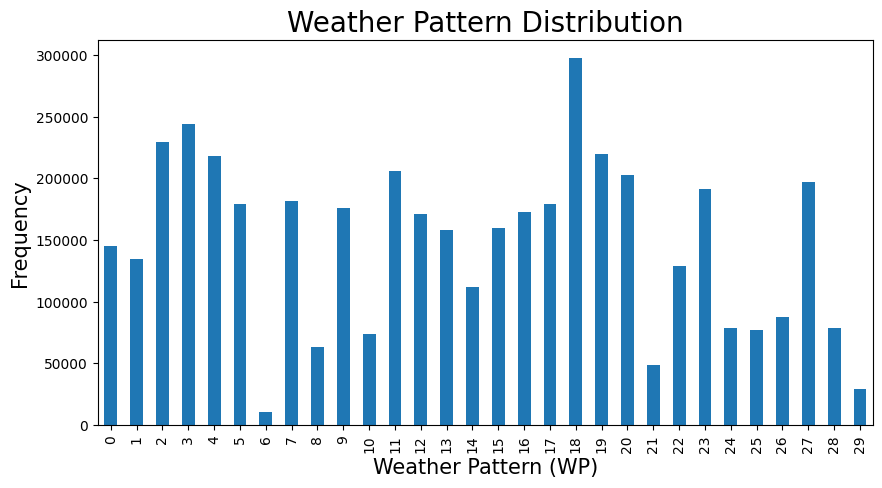

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager

df_geopotential["WP"].value_counts().sort_index().plot(kind="bar", figsize=(10,5))
font_path = '/content/Times-New-Roman.ttf'
font_manager.fontManager.addfont(font_path)
mpl.rcParams['font.family'] = 'Times New Roman'
plt.xlabel("Weather Pattern (WP)", fontsize=15)
plt.ylabel("Frequency", fontsize=15)
plt.title("Weather Pattern Distribution", fontsize=20)
plt.savefig('wp distribution.jpeg')
plt.show()

# Feature importance

In [ ]:
df_geopotential['year'] = df_geopotential['valid_time'].dt.year

yield_df = pd.read_csv("/content/dataset/MyDrive/dataset/-2/tea_production_summary_persian.csv")
climate_df = df_geopotential.drop(columns=['time', 'latitude', 'longitude', 'number', 'expver', 'number', 'expver', 'number', 'expver', 'WP', "pressure_level"], errors='ignore')

climate_yearly = climate_df.groupby(['year']).mean(numeric_only=True).reset_index()

merged_df = yield_df.merge(climate_yearly, on='year', how='inner')
merged_df

,year,ha,ton,ton/ha,tp,ssrd,e,d2m,t2m,msl,skt,swvl1,swvl2,swvl3,swvl4,z
0,1961,19979,10922.00,0.5467,0.000046,0.0,-0.000051,283.992551,288.949956,101207.992947,288.546150,0.105079,0.139812,0.153702,0.149154,56766.968662
1,1962,19979,11934.00,0.5973,0.000055,0.0,-0.000055,283.897910,288.831247,101319.335185,288.535299,0.111482,0.142006,0.151589,0.145879,56724.207350
2,1963,21154,12479.00,0.5899,0.000063,0.0,-0.000046,285.327830,289.529638,101179.907291,289.130123,0.120531,0.148890,0.158575,0.149256,56745.533318
3,1964,23256,10450.00,0.4493,0.000048,0.0,-0.000054,283.954870,288.934998,101241.671274,288.588054,0.107626,0.140681,0.150715,0.135082,56784.786643
4,1965,25079,12608.00,0.5027,0.000073,0.0,-0.000054,284.684015,289.322518,101278.530699,288.787054,0.118839,0.147758,0.154733,0.136549,56740.530525
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,2019,16229,90832.32,5.5969,0.000057,0.0,-0.000059,285.834201,291.282273,101278.497687,290.321896,0.107298,0.135250,0.139878,0.166165,56956.844919
59,2020,15867,94408.13,5.9500,0.000055,0.0,-0.000059,285.081318,290.594115,101358.199291,289.571786,0.109317,0.135330,0.142810,0.168200,56914.685394
60,2021,16512,113898.99,6.8980,0.000048,0.0,-0.000062,285.989109,291.886369,101269.833359,290.658390,0.092726,0.117933,0.135011,0.163490,57112.286626
61,2022,16512,93479.48,5.6613,0.000037,0.0,-0.000058,285.524551,291.542813,101237.251078,290.194912,0.089893,0.116215,0.133062,0.161941,57036.209109


In [ ]:
merged_df.to_csv("/content/dataset/MyDrive/dataset/-2/merged_climate_tea_yield.csv", index=False)

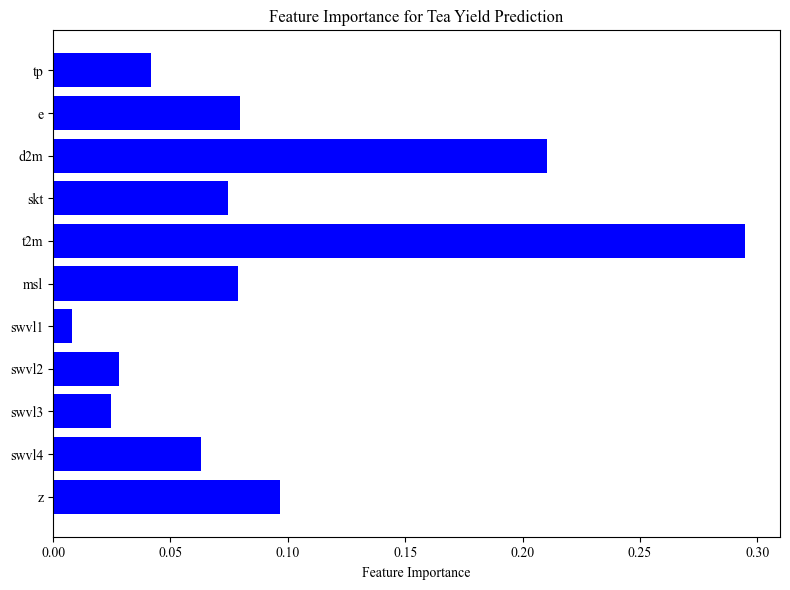

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import matplotlib as mpl
from matplotlib import font_manager

features = ['tp', 'e', 'd2m', 'skt', 't2m', 'msl', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'z']
target = 'ton/ha'

X = merged_df[features]
y = merged_df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

importances = model.feature_importances_
feature_names = X.columns

font_path = '/content/Times-New-Roman.ttf'
font_manager.fontManager.addfont(font_path)
mpl.rcParams['font.family'] = 'Times New Roman'

plt.figure(figsize=(8, 6))
plt.barh(feature_names, importances, color='blue')
plt.xlabel("Feature Importance")
plt.title("Feature Importance for Tea Yield Prediction")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('Feature Importance.jpeg')
plt.show()

# Correlations between weather patterns and Tea Yield

In [ ]:
df_geopotential

,valid_time,latitude,longitude,number,expver,tp,ssrd,e,d2m,t2m,msl,skt,swvl1,swvl2,swvl3,swvl4,pressure_level,z,WP,year
0,1960-04-01,35.5,48.50,0,1,1.430511e-06,0.0,-8.940697e-08,273.13280,277.36450,101211.625,273.63818,0.369118,3.566944e-01,0.237579,0.223511,500.0,55766.383,17,1960
1,1960-04-01,35.5,48.75,0,1,9.536743e-07,0.0,2.175569e-06,273.12890,276.66138,101249.875,272.75928,0.368859,3.592121e-01,0.252853,0.224304,500.0,55777.133,24,1960
2,1960-04-01,35.5,49.00,0,1,0.000000e+00,0.0,1.996756e-06,271.57422,275.06958,101276.625,270.39210,0.385262,3.838398e-01,0.266113,0.244598,500.0,55789.383,24,1960
3,1960-04-01,35.5,49.25,0,1,0.000000e+00,0.0,2.086163e-06,271.32617,274.62427,101258.125,270.26318,0.382927,3.795826e-01,0.272751,0.255417,500.0,55800.633,24,1960
4,1960-04-01,35.5,49.50,0,1,0.000000e+00,0.0,1.341104e-06,271.26953,274.89966,101243.375,269.93700,0.392708,3.803760e-01,0.263260,0.255325,500.0,55807.133,24,1960
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4451195,2023-10-31,38.5,53.50,0,1,0.000000e+00,0.0,-1.760421e-04,284.94653,291.57250,102727.000,290.72607,-0.000006,7.823110e-07,0.000006,0.000000,500.0,57198.617,22,2023
4451196,2023-10-31,38.5,53.75,0,1,0.000000e+00,0.0,-1.921055e-04,284.55980,291.27173,102730.250,290.87256,-0.000006,7.823110e-07,0.000006,0.000000,500.0,57191.117,22,2023
4451197,2023-10-31,38.5,54.00,0,1,1.907349e-06,0.0,-1.080332e-04,283.43286,290.45337,102738.250,289.70460,0.006830,7.823110e-07,0.042456,0.194305,500.0,57182.117,22,2023
4451198,2023-10-31,38.5,54.25,0,1,1.907349e-06,0.0,-1.847511e-06,280.84497,289.84595,102750.500,288.68310,0.008539,1.648732e-03,0.100500,0.292648,500.0,57173.367,28,2023


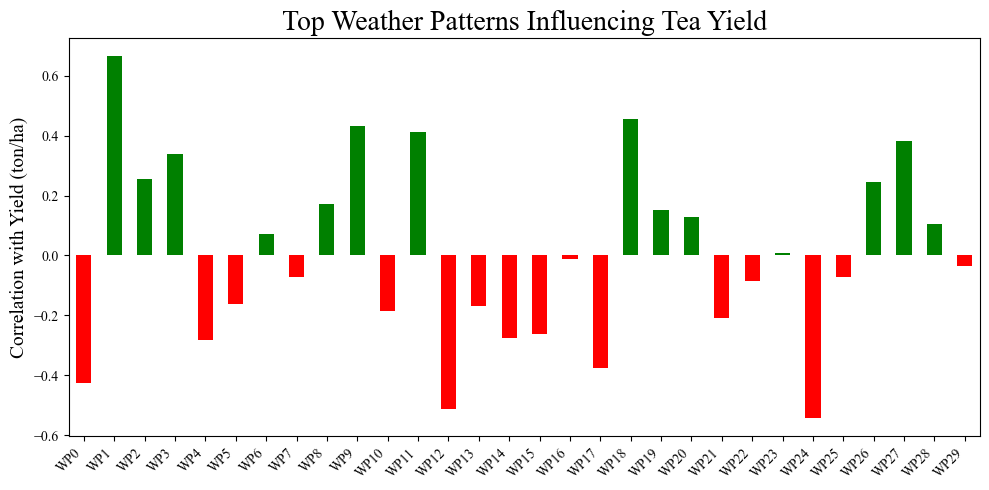

In [ ]:
unused_features = ['latitude', 'longitude', 'number', 'expver', 'tp',
       'ssrd', 'e', 'd2m', 't2m', 'msl', 'skt', 'swvl1',
       'swvl2', 'swvl3', 'swvl4', 'z', ]

df_wp = df_geopotential.drop(unused_features, axis=1)

wp_counts = df_wp.groupby(['year', 'WP']).size().unstack(fill_value=0).reset_index()

wp_counts.columns = ['year'] + [f'WP{col}' for col in wp_counts.columns[1:]]

df_with_wp = merged_df.merge(wp_counts, on='year', how='left') # Merge on 'year'

df_with_wp.columns = df_with_wp.columns.map(str)
#
# Calculate correlations
wp_cols = [col for col in df_with_wp.columns if col.startswith('WP')]
correlations = df_with_wp[wp_cols + ['ton/ha']].corr()['ton/ha'].drop('ton/ha')

# Create a color list based on whether correlation is positive or negative
colors = ['green' if val > 0 else 'red' for val in correlations]

# Plot
font_path = '/content/Times-New-Roman.ttf'
font_manager.fontManager.addfont(font_path)
mpl.rcParams['font.family'] = 'Times New Roman'

plt.figure(figsize=(10, 5))
correlations.plot(kind='bar', color=colors)
plt.ylabel('Correlation with Yield (ton/ha)', fontsize=14)
plt.title('Top Weather Patterns Influencing Tea Yield', fontsize=20)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('Correlation with Yield.jpeg')
plt.show()

In [ ]:
wp_cols

['WP0',
 'WP1',
 'WP2',
 'WP3',
 'WP4',
 'WP5',
 'WP6',
 'WP7',
 'WP8',
 'WP9',
 'WP10',
 'WP11',
 'WP12',
 'WP13',
 'WP14',
 'WP15',
 'WP16',
 'WP17',
 'WP18',
 'WP19',
 'WP20',
 'WP21',
 'WP22',
 'WP23',
 'WP24',
 'WP25',
 'WP26',
 'WP27',
 'WP28',
 'WP29',
 'WP_Index']

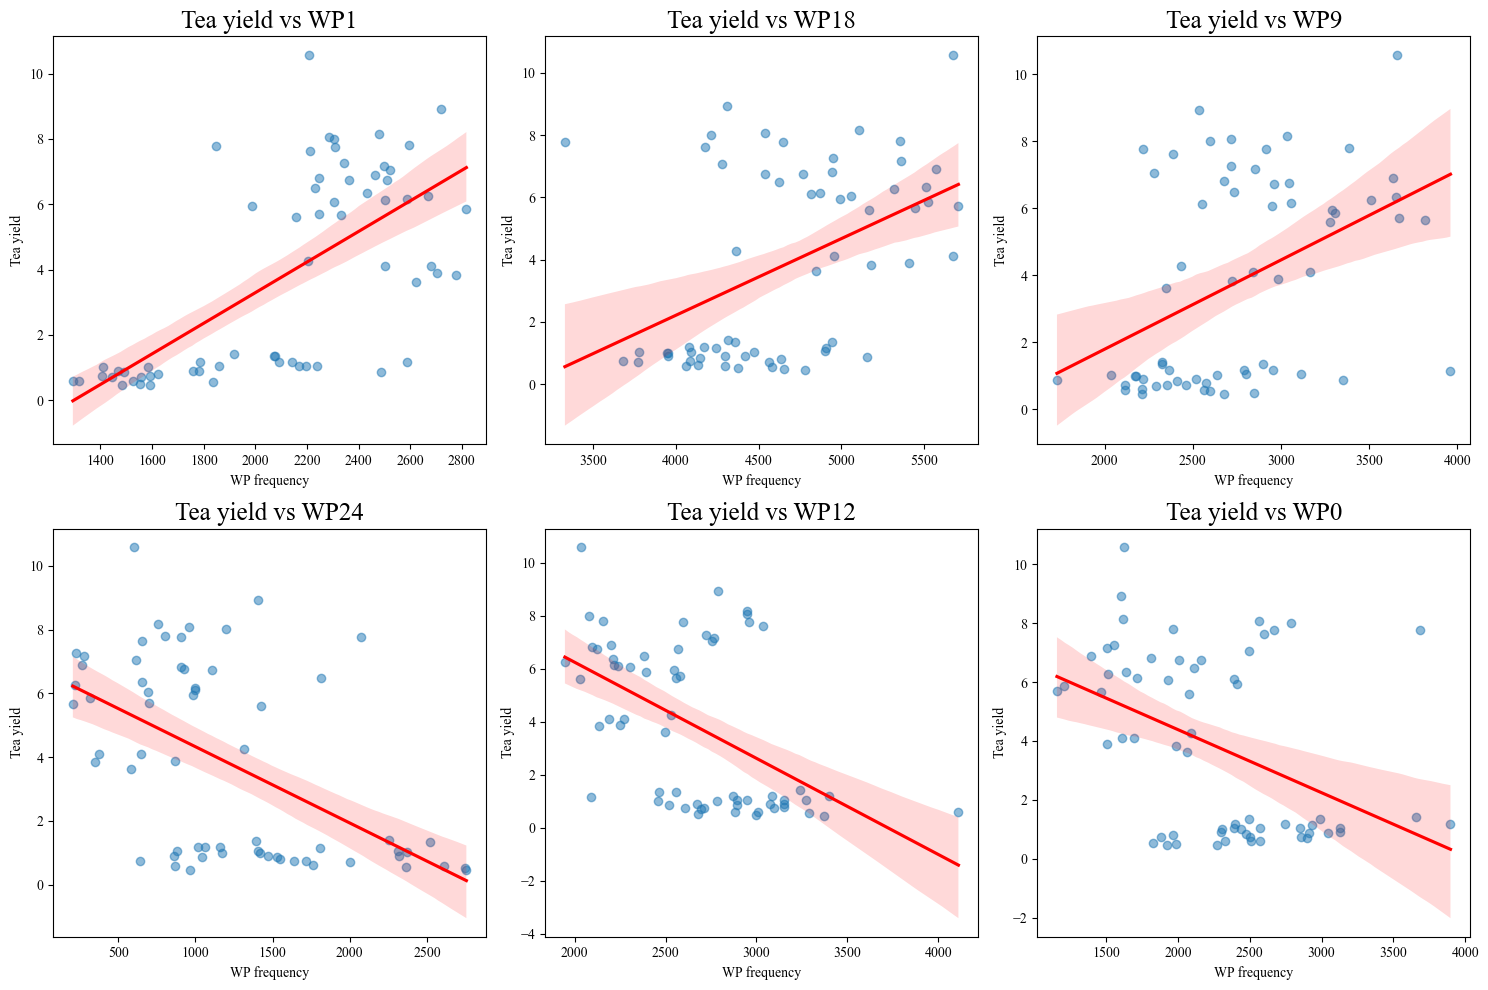

In [ ]:
# Calculate grid size
n_cols = 3
n_rows = 2

# Create subplot grid
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 10))

# Flatten axes array for easy iteration
axes = axes.flatten()
selected_wp_cols = ['WP1','WP18', 'WP9',
                    'WP24', 'WP12', 'WP0']
# Plot each weather pattern
for i, wp_column in enumerate(selected_wp_cols):
    sns.regplot(
        data=df_with_wp,
        x=wp_column,
        y='ton/ha',
        ax=axes[i],
        scatter_kws={'alpha':0.5},
        line_kws={'color':'red'}
    )
    axes[i].set_title(f"Tea yield vs {wp_column}", fontsize=18)
    axes[i].set_xlabel("WP frequency")
    axes[i].set_ylabel("Tea yield")

# Remove empty subplots
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig("correlations.jpeg")
plt.show()

In [ ]:
correlations

,ton/ha
WP0,-0.426701
WP1,0.665393
WP2,0.254341
WP3,0.337978
WP4,-0.284012
WP5,-0.162766
WP6,0.073068
WP7,-0.072245
WP8,0.170466
WP9,0.432167


In [ ]:
df_with_wp

,year,ha,ton,ton/ha,tp,ssrd,e,d2m,t2m,msl,...,WP20,WP21,WP22,WP23,WP24,WP25,WP26,WP27,WP28,WP29
0,1961,19979,10922.00,0.5467,0.000046,0.0,-0.000051,283.992551,288.949956,101207.992947,...,2555,682,2353,3321,2365,1360,1188,3123,1147,321
1,1962,19979,11934.00,0.5973,0.000055,0.0,-0.000055,283.897910,288.831247,101319.335185,...,2606,787,1583,2842,1763,1414,1890,2143,1502,445
2,1963,21154,12479.00,0.5899,0.000063,0.0,-0.000046,285.327830,289.529638,101179.907291,...,3517,857,965,3501,867,525,683,1758,1293,580
3,1964,23256,10450.00,0.4493,0.000048,0.0,-0.000054,283.954870,288.934998,101241.671274,...,2972,629,1783,3591,2755,1962,949,3734,962,262
4,1965,25079,12608.00,0.5027,0.000073,0.0,-0.000054,284.684015,289.322518,101278.530699,...,3227,860,1467,3536,2749,1398,1672,1790,956,676
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,2019,16229,90832.32,5.5969,0.000057,0.0,-0.000059,285.834201,291.282273,101278.497687,...,3008,729,1086,2941,1425,1412,1682,4229,1105,504
59,2020,15867,94408.13,5.9500,0.000055,0.0,-0.000059,285.081318,290.594115,101358.199291,...,2849,994,1676,2764,984,1431,1985,3641,1250,462
60,2021,16512,113898.99,6.8980,0.000048,0.0,-0.000062,285.989109,291.886369,101269.833359,...,2668,481,3416,3197,264,295,2299,4862,1048,368
61,2022,16512,93479.48,5.6613,0.000037,0.0,-0.000058,285.524551,291.542813,101237.251078,...,2570,459,2064,3528,206,716,1749,3825,1111,323


In [ ]:
df_with_wp.to_csv('/content/dataset/MyDrive/dataset/df_with_wp.csv')

# High, Medium, Low Yield Years

In [ ]:
yield_median = df_with_wp["ton/ha"].median()
print(f"Median Yield: {yield_median:.2f} tons/ha")

Median Yield: 3.84 tons/ha


In [ ]:
q1 = df_with_wp["ton/ha"].quantile(0.25)
q3 = df_with_wp["ton/ha"].quantile(0.75)

def classify(row):
  if row["ton/ha"] <= q1:
    return "Low"
  elif row["ton/ha"] >= q3:
      return "High"
  else:
      return "Medium"

df_with_wp["yield_class"] = df_with_wp.apply(classify, axis=1)
df_with_wp['yield_class']

,yield_class
0,Low
1,Low
2,Low
3,Low
4,Low
...,...
58,Medium
59,Medium
60,High
61,Medium


In [ ]:
print("High-yield years:", (df_with_wp["yield_class"] == "High").sum())
print("Medium-yield years:", (df_with_wp["yield_class"] == "Medium").sum())
print("Low-yield years:", (df_with_wp["yield_class"] == "Low").sum())

High-yield years: 16
Medium-yield years: 31
Low-yield years: 16


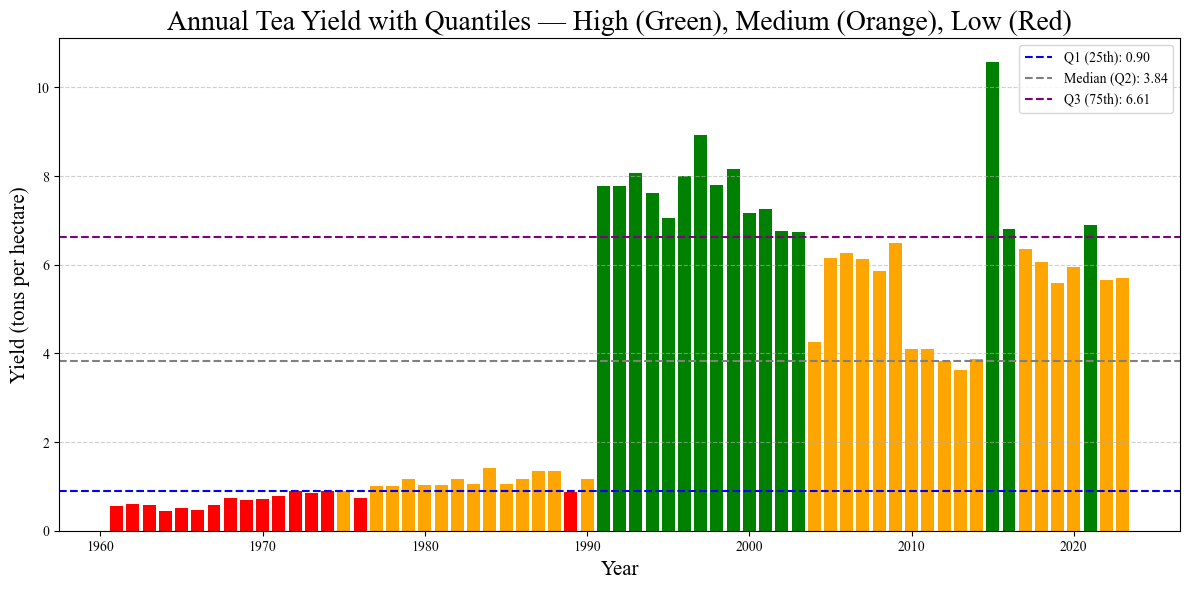

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager

df = df_with_wp.sort_values("year")
colors = df["yield_class"].map({ "High": "green", "Medium": "orange", "Low": "red" })

font_path = '/content/Times-New-Roman.ttf'
font_manager.fontManager.addfont(font_path)
mpl.rcParams['font.family'] = 'Times New Roman'

plt.figure(figsize=(12, 6))
plt.bar(df["year"], df["ton/ha"], color=colors)
plt.axhline(q1, color='blue', linestyle='--', label=f"Q1 (25th): {q1:.2f}")
plt.axhline(yield_median, color='gray', linestyle='--', label=f"Median (Q2): {yield_median:.2f}")
plt.axhline(q3, color='purple', linestyle='--', label=f"Q3 (75th): {q3:.2f}")
plt.title("Annual Tea Yield with Quantiles — High (Green), Medium (Orange), Low (Red)", fontsize=20)
plt.xlabel("Year", fontsize=15)
plt.ylabel("Yield (tons per hectare)", fontsize=15)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("Annual Tea Yield with Quantiles.jpeg")
plt.show()

In [ ]:
high_yield = df[df["yield_class"] == "High"]
low_yield = df[df["yield_class"] == "Low"]
medium_yield = df[df["yield_class"] == "Medium"]
wp_cols = [col for col in df.columns if col.startswith("WP")]

wp_mean_high = high_yield[wp_cols].mean()
wp_mean_low = low_yield[wp_cols].mean()
wp_mean_medium = medium_yield[wp_cols].mean()
diff_high_low = wp_mean_high - wp_mean_low
diff_high_med = wp_mean_high - wp_mean_medium
diff_med_low = wp_mean_medium - wp_mean_low

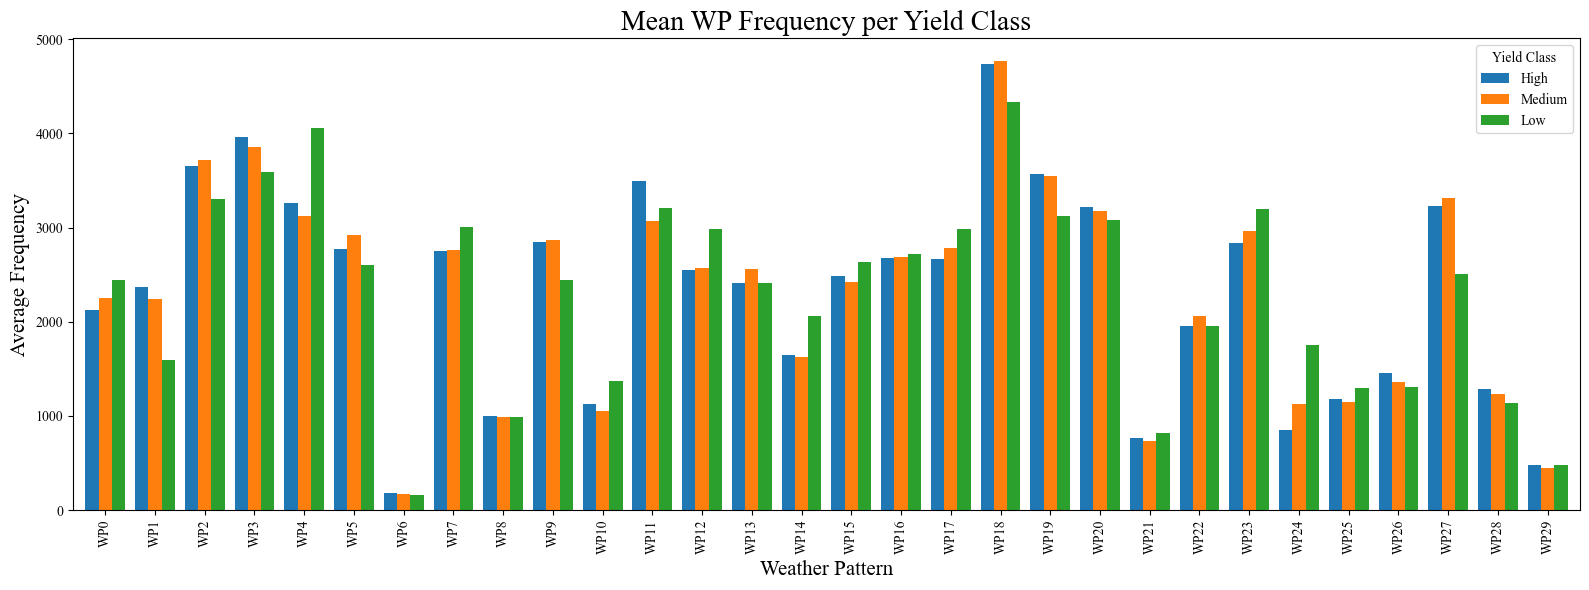

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager

df_mean_wp = pd.DataFrame({ "High": wp_mean_high, "Medium": wp_mean_medium, "Low": wp_mean_low })
df_mean_wp.plot(kind='bar', figsize=(16, 6), width=0.8)

font_path = '/content/Times-New-Roman.ttf'
font_manager.fontManager.addfont(font_path)
mpl.rcParams['font.family'] = 'Times New Roman'

plt.title("Mean WP Frequency per Yield Class", fontsize=20)
plt.ylabel("Average Frequency", fontsize=15)
plt.xlabel("Weather Pattern", fontsize=15)
plt.legend(title="Yield Class")
plt.tight_layout()
plt.savefig("Mean WP Frequency per Yield Class.png")
plt.show()

# weather pattern index

In [ ]:
diff_high_low.T

,0
WP0,-314.4375
WP1,779.0625
WP2,343.5000
WP3,367.5000
WP4,-795.1250
WP5,173.3125
WP6,20.3125
WP7,-249.6250
WP8,7.4375
WP9,411.3750


In [ ]:
positive_wps = diff_high_low[diff_high_low.T > 0].index.tolist()
negative_wps = diff_high_low[diff_high_low.T < 0].index.tolist()

print("Positive WPs:", positive_wps)
print("Negative WPs:", negative_wps)

df["WP_Index"] = (df[positive_wps].sum(axis=1) - df[negative_wps].sum(axis=1)) / (df[positive_wps].sum(axis=1) + df[negative_wps].sum(axis=1))

Positive WPs: ['WP1', 'WP2', 'WP3', 'WP5', 'WP6', 'WP8', 'WP9', 'WP11', 'WP18', 'WP19', 'WP20', 'WP22', 'WP26', 'WP27', 'WP28', 'WP29']
Negative WPs: ['WP0', 'WP4', 'WP7', 'WP10', 'WP12', 'WP13', 'WP14', 'WP15', 'WP16', 'WP17', 'WP21', 'WP23', 'WP24', 'WP25']


In [ ]:
df["WP_Index"]

,WP_Index
0,0.075399
1,0.001035
2,-0.023868
3,0.041639
4,0.008512
...,...
58,0.179928
59,0.151632
60,0.373400
61,0.256535


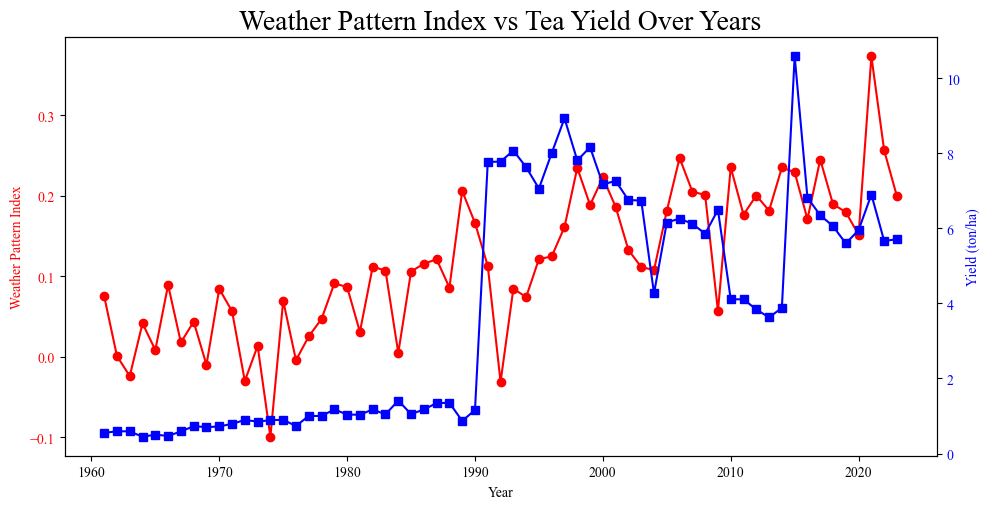

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns

def plot_dual_axis(df):

    fig, ax1 = plt.subplots(figsize=(10, 5.2))


    palette = sns.color_palette("Dark2")


    ax1.set_xlabel('Year')
    ax1.set_ylabel('Weather Pattern Index', color='red')
    line1 = ax1.plot(df['year'], df['WP_Index'], color='red', label='Weather Pattern Index', marker='o')
    ax1.tick_params(axis='y', labelcolor='red')


    ax2 = ax1.twinx()
    ax2.set_ylabel('Yield (ton/ha)', color='blue')
    line2 = ax2.plot(df['year'], df['ton/ha'], color='blue', label='Yield', marker='s')
    ax2.tick_params(axis='y', labelcolor='blue')


    plt.title("Weather Pattern Index vs Tea Yield Over Years", fontsize=20)
    fig.tight_layout()
    plt.show()


df_sorted = df.sort_values('year', ascending=True)
plot_dual_axis(df_sorted)

Mean Squared Error: 5.981701011135031
R-squared: 0.3392266684373373


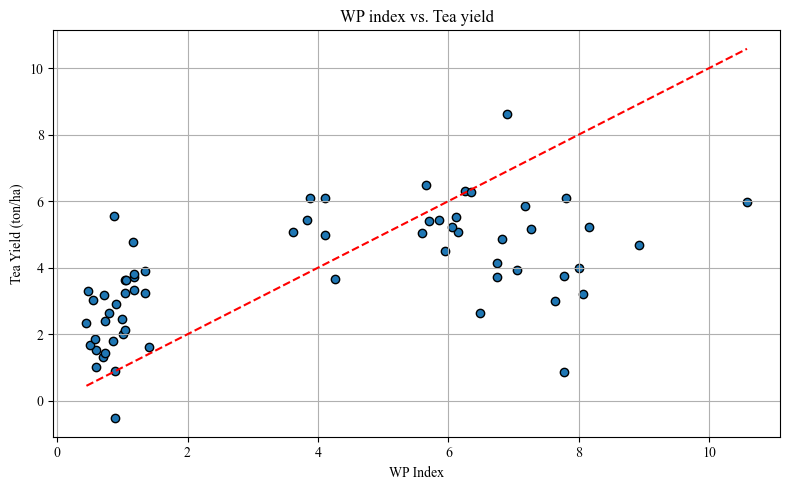

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

X = df[["WP_Index"]]
y = df["ton/ha"]

poly = PolynomialFeatures(degree=2)
X_poly = poly.fit_transform(X)

model = LinearRegression()
model.fit(X_poly, y)

y_pred = model.predict(X_poly)

mse = mean_squared_error(y, y_pred)
r2 = r2_score(y, y_pred)

print("Mean Squared Error:", mse)
print("R-squared:", r2)

plt.figure(figsize=(8, 5))
plt.scatter(y, y_pred, edgecolors='k')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("WP Index")
plt.ylabel("Tea Yield (ton/ha)")
plt.title("WP index vs. Tea yield")
plt.grid(True)
plt.tight_layout()
plt.show()

## New Section

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
import numpy as np

wp_cols = [col for col in df.columns if col.startswith('WP')]

X = df[wp_cols]
y = df['yield_class']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split( X_scaled, y, test_size=0.2, random_state=42 )

models = { "LogisticRegression": LogisticRegression(max_iter=1000),
          "RandomForest": RandomForestClassifier(),
           "SVM": SVC(), "DecisionTree": DecisionTreeClassifier(),
           "KNN": KNeighborsClassifier() }

for name, model in models.items():
  model.fit(X_train, y_train)
  preds = model.predict(X_test)
  acc = accuracy_score(y_test, preds)
  print(f"\n{name} - Accuracy: {acc:.3f}")
  print(classification_report(y_test, preds))

for name, model in models.items():
  scores = cross_val_score(model, X_scaled, y, cv=5)
  print(f"{name} — Mean Accuracy: {np.mean(scores):.3f} ± {np.std(scores):.3f}")


LogisticRegression - Accuracy: 0.615
              precision    recall  f1-score   support

        High       1.00      0.25      0.40         4
         Low       0.75      0.75      0.75         4
      Medium       0.50      0.80      0.62         5

    accuracy                           0.62        13
   macro avg       0.75      0.60      0.59        13
weighted avg       0.73      0.62      0.59        13


RandomForest - Accuracy: 0.462
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         4
         Low       0.67      0.50      0.57         4
      Medium       0.40      0.80      0.53         5

    accuracy                           0.46        13
   macro avg       0.36      0.43      0.37        13
weighted avg       0.36      0.46      0.38        13


SVM - Accuracy: 0.462
              precision    recall  f1-score   support

        High       0.00      0.00      0.00         4
         Low       0.67      0.50   

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/m

LogisticRegression — Mean Accuracy: 0.414 ± 0.130
RandomForest — Mean Accuracy: 0.572 ± 0.075
SVM — Mean Accuracy: 0.619 ± 0.056
DecisionTree — Mean Accuracy: 0.536 ± 0.139
KNN — Mean Accuracy: 0.418 ± 0.214


In [ ]:
df

,year,ha,ton,ton/ha,tp,ssrd,e,d2m,t2m,msl,...,WP22,WP23,WP24,WP25,WP26,WP27,WP28,WP29,yield_class,WP_Index
0,1961,19979,10922.00,0.5467,0.000046,0.0,-0.000051,283.992551,288.949956,101207.992947,...,2353,3321,2365,1360,1188,3123,1147,321,Low,0.075399
1,1962,19979,11934.00,0.5973,0.000055,0.0,-0.000055,283.897910,288.831247,101319.335185,...,1583,2842,1763,1414,1890,2143,1502,445,Low,0.001035
2,1963,21154,12479.00,0.5899,0.000063,0.0,-0.000046,285.327830,289.529638,101179.907291,...,965,3501,867,525,683,1758,1293,580,Low,-0.023868
3,1964,23256,10450.00,0.4493,0.000048,0.0,-0.000054,283.954870,288.934998,101241.671274,...,1783,3591,2755,1962,949,3734,962,262,Low,0.041639
4,1965,25079,12608.00,0.5027,0.000073,0.0,-0.000054,284.684015,289.322518,101278.530699,...,1467,3536,2749,1398,1672,1790,956,676,Low,0.008512
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
58,2019,16229,90832.32,5.5969,0.000057,0.0,-0.000059,285.834201,291.282273,101278.497687,...,1086,2941,1425,1412,1682,4229,1105,504,Medium,0.179928
59,2020,15867,94408.13,5.9500,0.000055,0.0,-0.000059,285.081318,290.594115,101358.199291,...,1676,2764,984,1431,1985,3641,1250,462,Medium,0.151632
60,2021,16512,113898.99,6.8980,0.000048,0.0,-0.000062,285.989109,291.886369,101269.833359,...,3416,3197,264,295,2299,4862,1048,368,High,0.373400
61,2022,16512,93479.48,5.6613,0.000037,0.0,-0.000058,285.524551,291.542813,101237.251078,...,2064,3528,206,716,1749,3825,1111,323,Medium,0.256535


In [ ]:
df.columns

Index(['year', 'ha', 'ton', 'ton/ha', 'tp', 'ssrd', 'e', 'd2m', 't2m', 'msl',
       'skt', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'z', 'WP0', 'WP1', 'WP2',
       'WP3', 'WP4', 'WP5', 'WP6', 'WP7', 'WP8', 'WP9', 'WP10', 'WP11', 'WP12',
       'WP13', 'WP14', 'WP15', 'WP16', 'WP17', 'WP18', 'WP19', 'WP20', 'WP21',
       'WP22', 'WP23', 'WP24', 'WP25', 'WP26', 'WP27', 'WP28', 'WP29',
       'yield_class', 'WP_Index'],
      dtype='object')

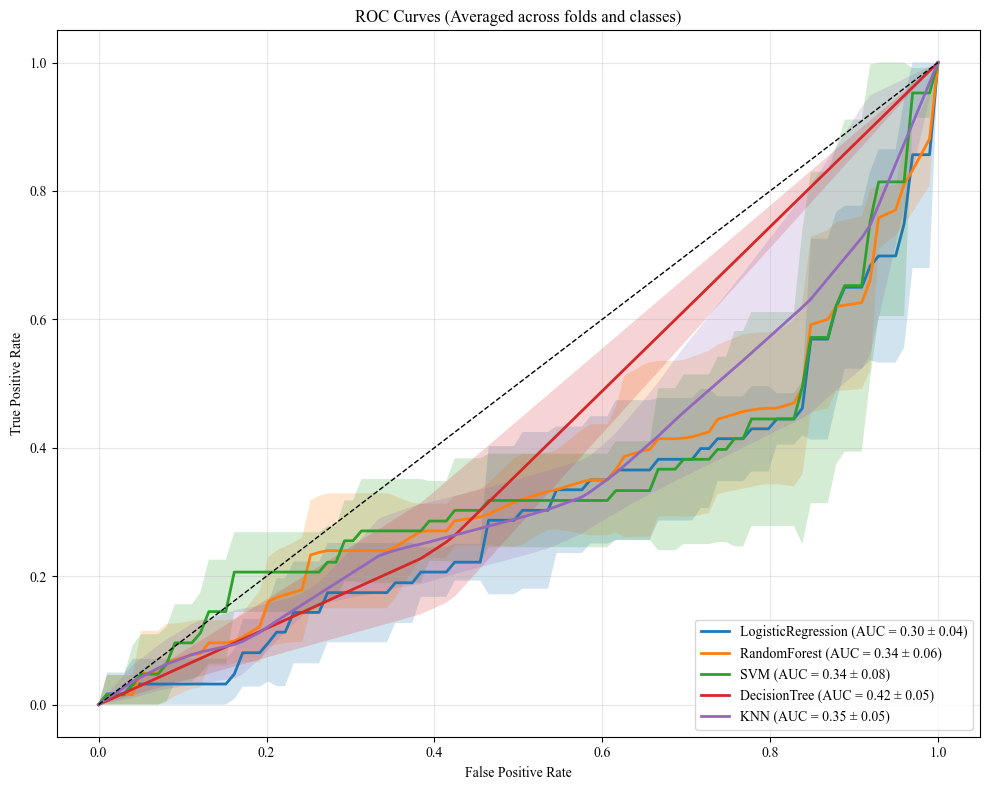

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.metrics import roc_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier


features = ['tp', 'skt', 'e', 'd2m', 't2m', 'msl', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'z']
X = df[features]
y = df["yield_class"]

# Binarize labels for ROC computation (One-vs-Rest)
classes = ["Low", "Medium", "High"]
y_bin = label_binarize(y, classes=classes)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Define models
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(),
    "SVM": SVC(probability=True),
    "DecisionTree": DecisionTreeClassifier(),
    "KNN": KNeighborsClassifier()
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Plot ROC curves for each model
plt.figure(figsize=(10, 8))
mean_fpr = np.linspace(0, 1, 100)

for name, model in models.items():
    tprs = []
    aucs = []

    for train_idx, test_idx in cv.split(X_scaled, y):
        X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
        y_train_bin = label_binarize(y.iloc[train_idx], classes=classes)
        y_test_bin = label_binarize(y.iloc[test_idx], classes=classes)

        model.fit(X_train, y.iloc[train_idx])
        y_score = model.predict_proba(X_test)

        # Average ROC curve over all classes
        fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(auc(fpr, tpr))

    # Mean and std AUC
    mean_tpr = np.mean(tprs, axis=0)
    mean_auc = np.mean(aucs)
    std_auc = np.std(aucs)
    plt.plot(mean_fpr, mean_tpr, lw=2,
             label=f"{name} (AUC = {mean_auc:.2f} ± {std_auc:.2f})")

    # Optional shaded area
    std_tpr = np.std(tprs, axis=0)
    plt.fill_between(mean_fpr,
                     np.maximum(mean_tpr - std_tpr, 0),
                     np.minimum(mean_tpr + std_tpr, 1),
                     alpha=0.2)

# Plot formatting
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (Averaged across folds and classes)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



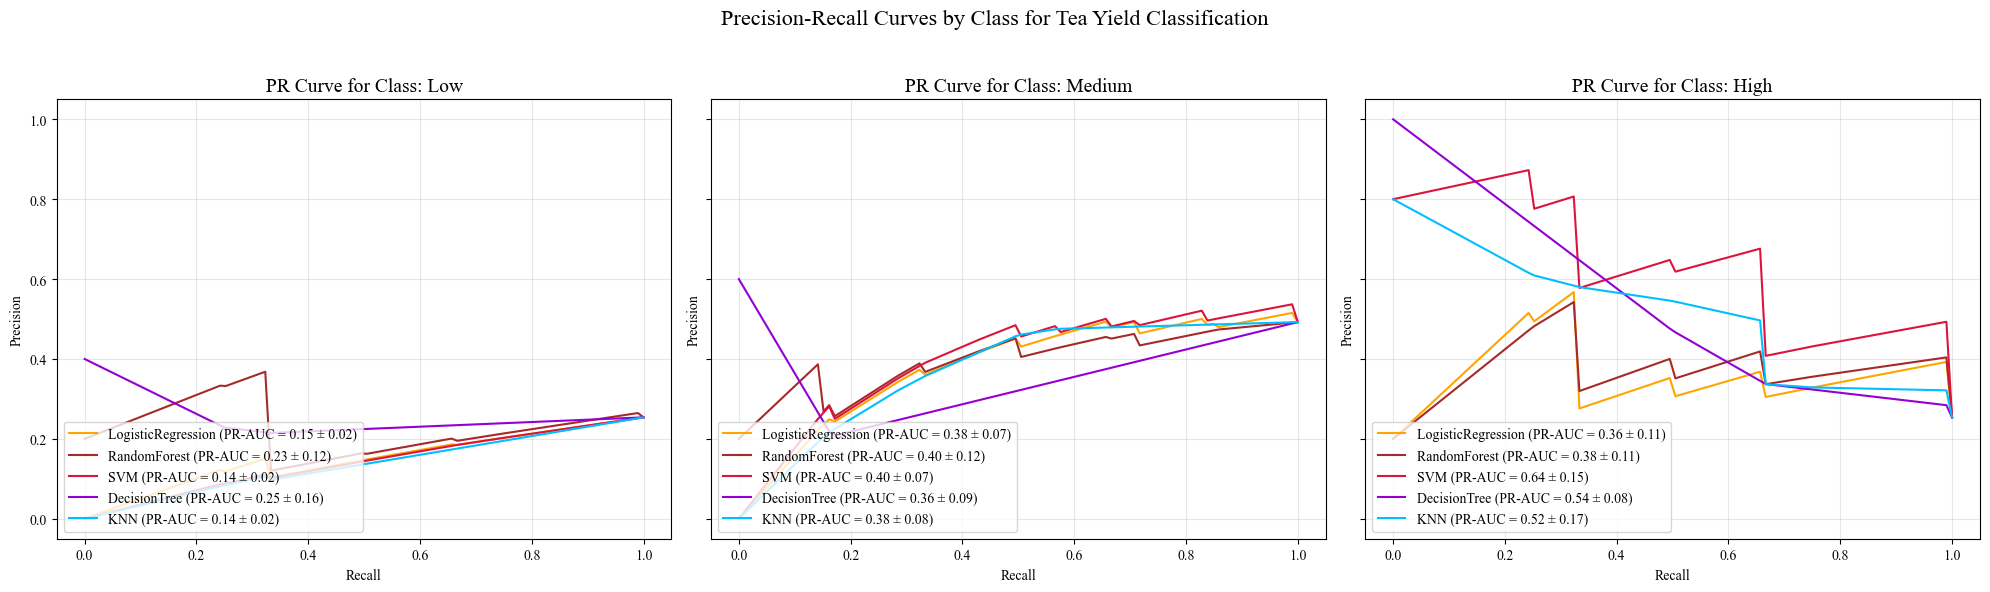

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import label_binarize, StandardScaler
from sklearn.metrics import precision_recall_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# Prepare data
features = ['tp', 'skt', 'e', 'd2m', 't2m', 'msl', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'z']
X = df[features]
y = df["yield_class"]
classes = ["Low", "Medium", "High"]
y_bin = label_binarize(y, classes=classes)

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Define models
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(),
    "SVM": SVC(probability=True),
    "DecisionTree": DecisionTreeClassifier(),
    "KNN": KNeighborsClassifier()
}

colors = {
    "LogisticRegression": "orange",
    "RandomForest": "brown",
    "SVM": "crimson",
    "DecisionTree": "darkviolet",
    "KNN": "deepskyblue"
}

# Plotting setup
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# For each class
for class_idx, class_name in enumerate(classes):
    ax = axes[class_idx]
    for model_name, model in models.items():
        precisions, recalls, pr_aucs = [], [], []
        for train_idx, test_idx in cv.split(X_scaled, y):
            X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
            y_train_bin = label_binarize(y_train, classes=classes)
            y_test_bin = label_binarize(y_test, classes=classes)

            model.fit(X_train, y_train)
            y_score = model.predict_proba(X_test)
            precision, recall, _ = precision_recall_curve(y_test_bin[:, class_idx], y_score[:, class_idx])
            pr_auc = auc(recall, precision)
            precisions.append(np.interp(np.linspace(0, 1, 100), recall[::-1], precision[::-1]))
            pr_aucs.append(pr_auc)

        mean_precision = np.mean(precisions, axis=0)
        mean_auc = np.mean(pr_aucs)
        std_auc = np.std(pr_aucs)
        ax.plot(np.linspace(0, 1, 100), mean_precision,
                label=f"{model_name} (PR-AUC = {mean_auc:.2f} ± {std_auc:.2f})",
                color=colors[model_name])

    ax.set_title(f"PR Curve for Class: {class_name}", fontsize=14)
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.legend(loc="lower left")
    ax.grid(True, alpha=0.3)

fig.suptitle("Precision-Recall Curves by Class for Tea Yield Classification", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Mean Sea Level Pressure (MSLP) Anomalies by WP

In [ ]:
!pip install cartopy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 31.5 MB/s eta 0:00:00


In [ ]:
df_geopotential

,valid_time,latitude,longitude,number,expver,tp,ssrd,e,d2m,t2m,msl,skt,swvl1,swvl2,swvl3,swvl4,pressure_level,z,WP,year
0,1960-04-01,35.5,48.50,0,1,1.430511e-06,0.0,-8.940697e-08,273.13280,277.36450,101211.625,273.63818,0.369118,3.566944e-01,0.237579,0.223511,500.0,55766.383,17,1960
1,1960-04-01,35.5,48.75,0,1,9.536743e-07,0.0,2.175569e-06,273.12890,276.66138,101249.875,272.75928,0.368859,3.592121e-01,0.252853,0.224304,500.0,55777.133,24,1960
2,1960-04-01,35.5,49.00,0,1,0.000000e+00,0.0,1.996756e-06,271.57422,275.06958,101276.625,270.39210,0.385262,3.838398e-01,0.266113,0.244598,500.0,55789.383,24,1960
3,1960-04-01,35.5,49.25,0,1,0.000000e+00,0.0,2.086163e-06,271.32617,274.62427,101258.125,270.26318,0.382927,3.795826e-01,0.272751,0.255417,500.0,55800.633,24,1960
4,1960-04-01,35.5,49.50,0,1,0.000000e+00,0.0,1.341104e-06,271.26953,274.89966,101243.375,269.93700,0.392708,3.803760e-01,0.263260,0.255325,500.0,55807.133,24,1960
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4451195,2023-10-31,38.5,53.50,0,1,0.000000e+00,0.0,-1.760421e-04,284.94653,291.57250,102727.000,290.72607,-0.000006,7.823110e-07,0.000006,0.000000,500.0,57198.617,22,2023
4451196,2023-10-31,38.5,53.75,0,1,0.000000e+00,0.0,-1.921055e-04,284.55980,291.27173,102730.250,290.87256,-0.000006,7.823110e-07,0.000006,0.000000,500.0,57191.117,22,2023
4451197,2023-10-31,38.5,54.00,0,1,1.907349e-06,0.0,-1.080332e-04,283.43286,290.45337,102738.250,289.70460,0.006830,7.823110e-07,0.042456,0.194305,500.0,57182.117,22,2023
4451198,2023-10-31,38.5,54.25,0,1,1.907349e-06,0.0,-1.847511e-06,280.84497,289.84595,102750.500,288.68310,0.008539,1.648732e-03,0.100500,0.292648,500.0,57173.367,28,2023


/usr/local/lib/python3.11/dist-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.11/dist-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.11/dist-packages/cartopy/io/__init__.py:241: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


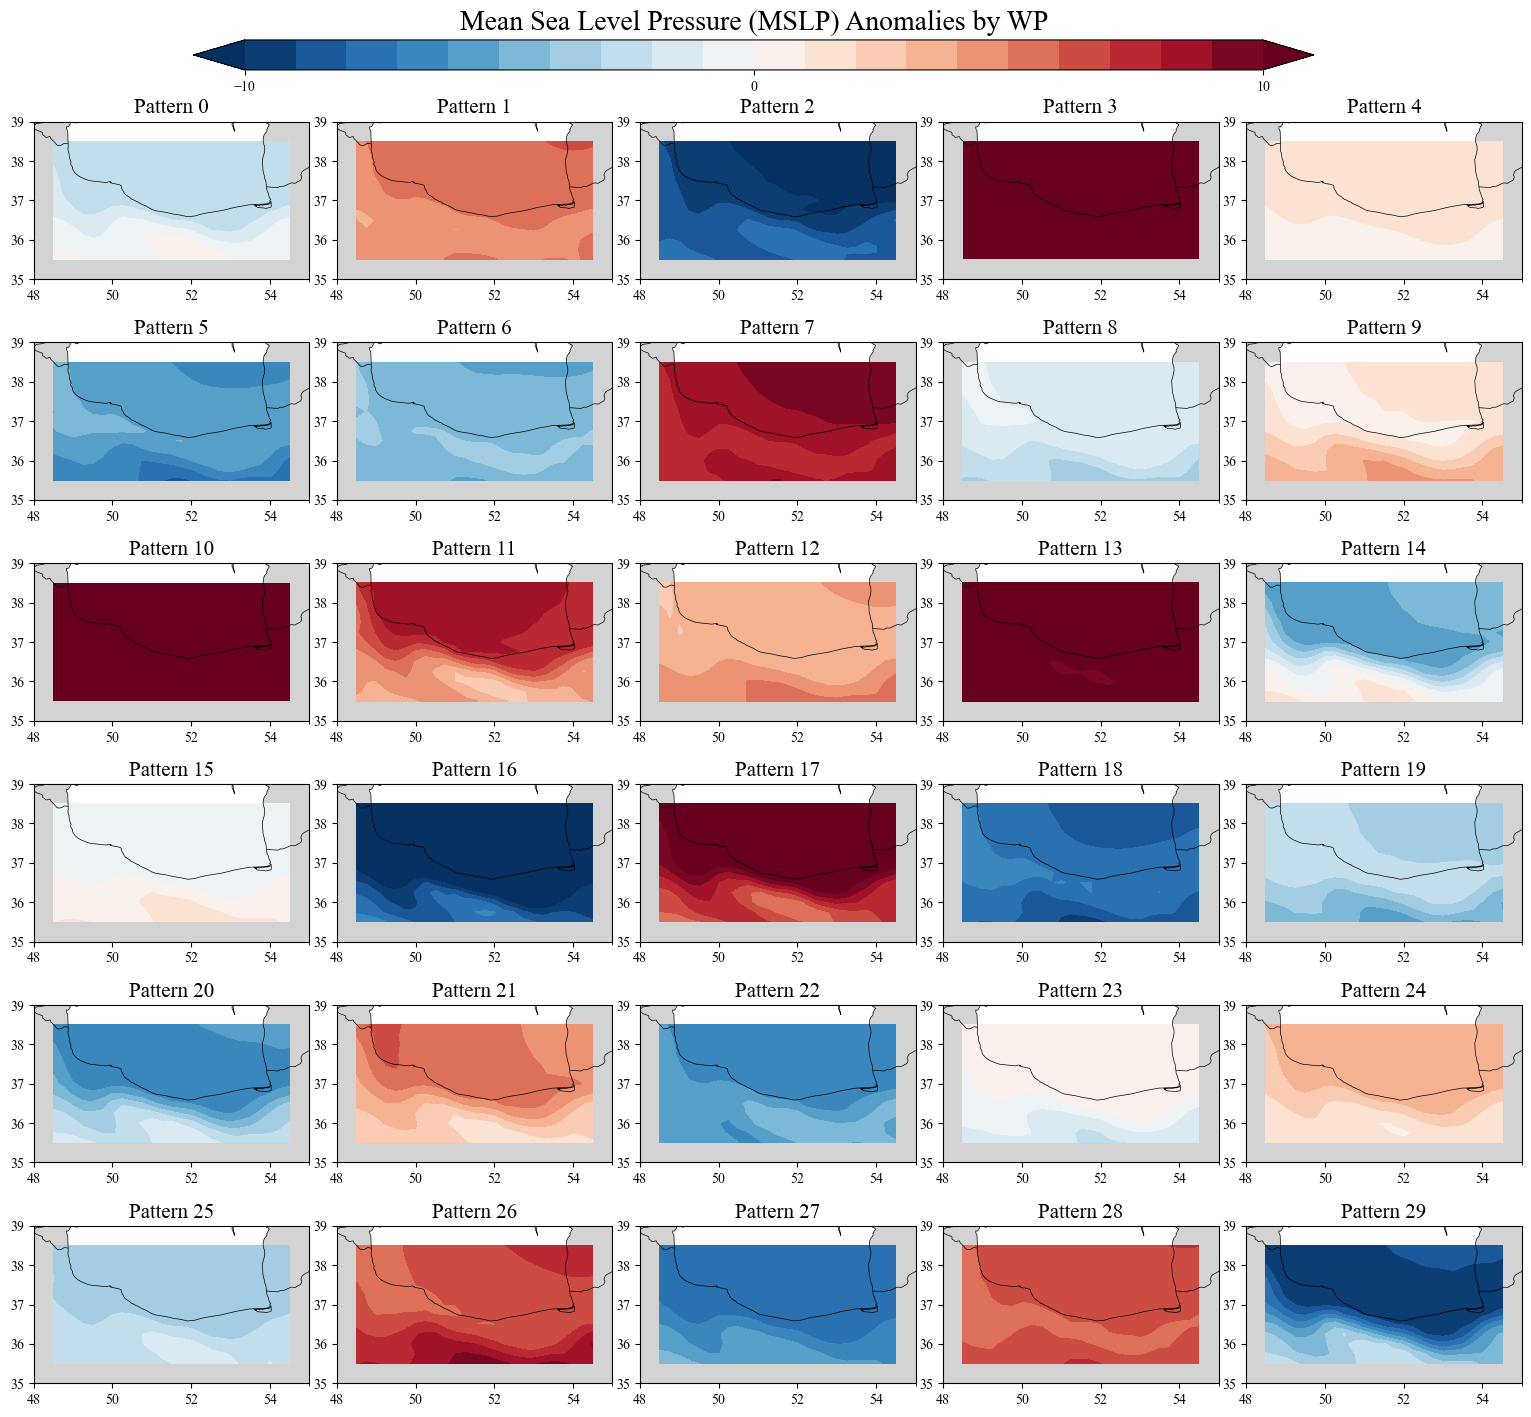

In [ ]:
import xarray as xr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
from matplotlib import font_manager

file_path = "/content/dataset/MyDrive/dataset/weatherpatterns/data_stream-oper_stepType-instant.nc"
ds = xr.open_dataset(file_path)

msl = ds['msl'] /100.0
time_coord = ds['valid_time']
lat = ds['latitude'].values
lon = ds['longitude'].values

n_clusters = 30

nt, nlat, nlon = msl.shape
msl_2d = msl.values.reshape(nt, nlat*nlon)
wp_labels = kmeans.fit_predict(msl_2d)

mean_msl = msl.mean(dim='valid_time')

msl_anom = msl - mean_msl

msl_anom_data = msl_anom.values

mean_maps = []
for wp_id in range(n_clusters):
    idx = (wp_labels == wp_id)
    if np.sum(idx) < 1:
        mean_maps.append(None)
        continue
    mean_wp = msl_anom_data[idx, :, :].mean(axis=0)
    mean_maps.append(mean_wp)

fig, axs = plt.subplots(6, 5, figsize=(16, 15),
                        subplot_kw={'projection': ccrs.PlateCarree()})
axs = axs.ravel()

levels = np.linspace(-10, 10, 21)

for i in range(n_clusters):
    ax = axs[i]
    ax.set_title(f"Pattern {i}", fontsize=15)

    ax.add_feature(cfeature.LAND, facecolor='lightgray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.set_extent([48, 55, 35, 39], crs=ccrs.PlateCarree())
    ax.set_xticks([48, 55], minor=True)
    ax.set_yticks([35, 39], minor=True)

    if mean_maps[i] is None:
        ax.text(0.5, 0.5, "No Data", transform=ax.transAxes,
                ha='center', va='center', color='red', fontsize=12)
        continue

    cf = ax.contourf(lon, lat, mean_maps[i],
                     levels=levels, cmap='RdBu_r', extend='both')

cax = fig.add_axes([0.15, 0.92, 0.7, 0.02])
cbar = fig.colorbar(cf, cax=cax, orientation='horizontal')

cbar.set_ticks([-10, 0, 10])

font_path = "/content/Times-New-Roman.ttf"
font_manager.fontManager.addfont(font_path)
mpl.rcParams['font.family'] = 'Times New Roman'

plt.subplots_adjust(left=0.05, right=0.98, bottom=0.03, top=0.90, wspace=0.1, hspace=0.1)
plt.suptitle("Mean Sea Level Pressure (MSLP) Anomalies by WP", fontsize=20, y=0.96)
plt.savefig("weather_patterns.jpeg")
plt.show()


['WP0', 'WP1', 'WP2', 'WP3', 'WP4', 'WP5', 'WP6', 'WP7', 'WP8', 'WP9', 'WP10', 'WP11', 'WP12', 'WP13', 'WP14', 'WP15', 'WP16', 'WP17', 'WP18', 'WP19', 'WP20', 'WP21', 'WP22', 'WP23', 'WP24', 'WP25', 'WP26', 'WP27', 'WP28', 'WP29']


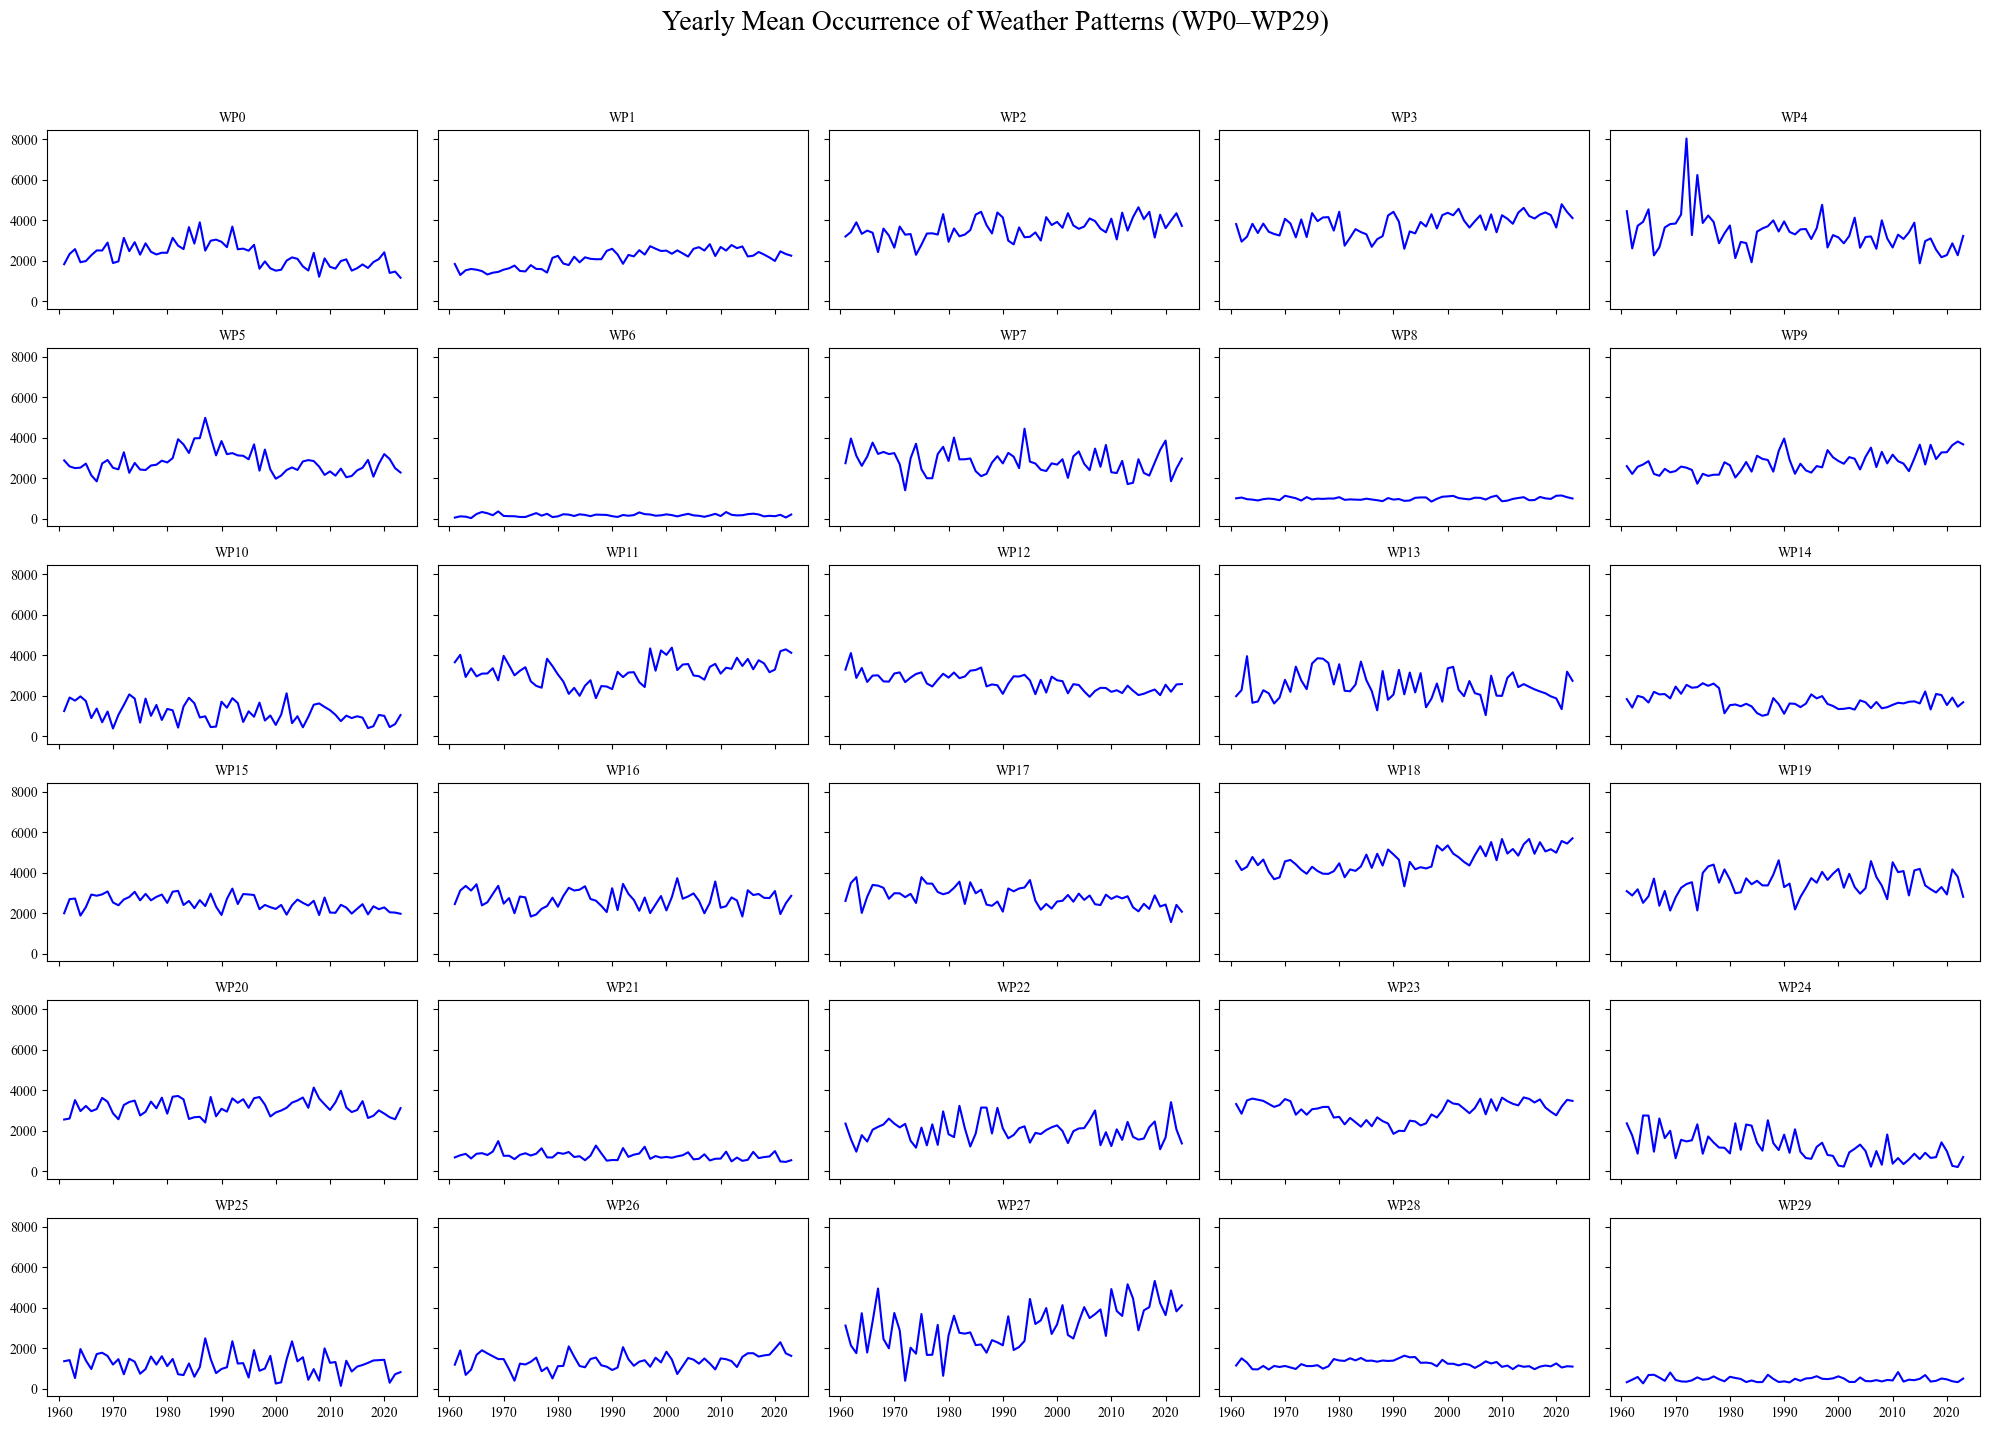

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Load your dataset
file_path = "/content/dataset/MyDrive/dataset/df_with_wp.csv"
df = pd.read_csv(file_path)

# Ensure 'year' column is integer
df['year'] = df['year'].astype(int)

# Identify WP columns
wp_columns = [col for col in df.columns if col.startswith('WP')]

# Group by year and calculate mean occurrence
df_grouped = df.groupby('year')[wp_columns].mean().reset_index()

# Plot
fig, axes = plt.subplots(nrows=6, ncols=5, figsize=(20, 15), sharex=True, sharey=True)
axes = axes.flatten()

print(wp_columns)
for i, wp in enumerate(wp_columns):
    ax = axes[i]
    sns.lineplot(data=df_grouped, x='year', y=wp, ax=ax, color='blue')
    ax.set_title(wp, fontsize=10)
    ax.set_xlabel('')
    ax.set_ylabel('')

# Remove empty subplots
for ax in axes[len(wp_columns):]:
    fig.delaxes(ax)

# Final formatting
mpl.rcParams['font.family'] = 'Times New Roman'
fig.suptitle('Yearly Mean Occurrence of Weather Patterns (WP0–WP29)', fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("Yearly Mean Occurrence of Weather Patterns.jpeg")
plt.show()

In [13]:
import pandas as pd

# ---------------------------------------------
# 1. بارگذاری داده‌
file_path = "/content/dataset/MyDrive/dataset/df_with_wp.csv"
df = pd.read_csv(file_path)

# 2. اطمینان از نوع عددی بودن سال
df['year'] = df['year'].astype(int)

# 3. استخراج ستون‌های WP
wp_columns = [col for col in df.columns if col.startswith('WP')]

# اگر هر ردیف نشان‌دهندۀ «یک روز» است و ستون‌های WP فقط مقدار 0/1 دارند:
# فراوانی سالانه = مجموع (sum)
df_yearly_counts = (
    df.groupby('year')[wp_columns]
      .sum()                      # جمع تعداد روزهایی که هر WP رخ داده
)

# ---------------------------------------------
# 4. نگه‌داشتن فقط سال‌های مدنظر
target_years = [1961, 1970, 1980, 1990, 2000, 2010, 2020, 2023]
table = df_yearly_counts.loc[target_years]

# اگر ستونی دارید که میانگین روزانه (۰–۱) است، کافی است پس از groupby از mean()
# استفاده کرده و ضرب در تعداد روزهای فصل رشد یا 365 کنید.
# ---------------------------------------------
# 5. مشاهده/ذخیره جدول
table_T = table.T

print(table_T)


table_T.to_excel("WP_frequency_selected_years.xlsx")


year  1961  1970  1980  1990  2000  2010  2020  2023
WP0   1827  1885  2391  2934  1506  1696  2414  1157
WP1   1837  1556  2239  2589  2497  2679  1986  2248
WP2   3198  2644  2936  4136  3918  4077  3609  3722
WP3   3811  4071  4421  4417  4370  4250  3643  4108
WP4   4449  3838  3739  3943  3153  2652  2279  3223
WP5   2881  2515  2779  3836  1976  2337  3193  2282
WP6     52   133   113   121   212   128   120   202
WP7   2742  3241  2851  2733  2673  2294  3861  2973
WP8   1004  1131  1062   942  1102   859  1132   997
WP9   2597  2355  2639  3962  2851  3163  3287  3672
WP10  1241   379  1347  1704   555  1285  1004  1045
WP11  3655  3972  3050  2326  4022  3094  3292  4125
WP12  3291  3099  2895  2092  2765  2191  2544  2577
WP13  1979  2787  3558  2059  3354  1992  1870  2737
WP14  1834  2451  1532  1109  1339  1549  1539  1678
WP15  2000  2533  2511  1914  2212  2034  2289  1974
WP16  2454  2475  2321  3238  2140  2271  3098  2859
WP17  2608  2990  3016  2079  2580  2708  2431

In [9]:
df_yearly_counts

,WP0,WP1,WP2,WP3,WP4,WP5,WP6,WP7,WP8,WP9,...,WP20,WP21,WP22,WP23,WP24,WP25,WP26,WP27,WP28,WP29
year,,,,,,,,,,,,,,,,,,,,,
1961,1827,1837,3198,3811,4449,2881,52,2742,1004,2597,...,2555,682,2353,3321,2365,1360,1188,3123,1147,321
1962,2331,1293,3419,2943,2606,2584,114,3966,1043,2212,...,2606,787,1583,2842,1763,1414,1890,2143,1502,445
1963,2571,1526,3898,3189,3726,2499,97,3112,963,2566,...,3517,857,965,3501,867,525,683,1758,1293,580
1964,1922,1590,3328,3825,3923,2523,26,2612,940,2678,...,2972,629,1783,3591,2755,1962,949,3734,962,262
1965,1984,1554,3489,3370,4541,2722,229,3069,899,2846,...,3227,860,1467,3536,2749,1398,1672,1790,956,676
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019,2079,2158,4275,4254,2171,2712,140,3403,976,3276,...,3008,729,1086,2941,1425,1412,1682,4229,1105,504
2020,2414,1986,3609,3643,2279,3193,120,3861,1132,3287,...,2849,994,1676,2764,984,1431,1985,3641,1250,462
2021,1394,2463,3986,4792,2858,2948,189,1849,1145,3635,...,2668,481,3416,3197,264,295,2299,4862,1048,368
